In [ ]:
import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as nnF
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import ARMAConv

from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import models
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, log_loss, roc_auc_score

/home/snu/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
data = np.load('/home/snu/Downloads/breastmnist_224.npz', allow_pickle=True)
all_images = np.concatenate([data['train_images'], data['val_images'], data['test_images']], axis=0)
all_labels = np.concatenate([data['train_labels'], data['val_labels'], data['test_labels']], axis=0).squeeze()

images = all_images.astype(np.float32) / 255.0
images = np.repeat(images[:, None, :, :], 3, axis=1)  # (N,3,224,224)
X = torch.tensor(images)
y = torch.tensor(all_labels).long()
print("Images, labels shapes:", X.shape, y.shape)

Images, labels shapes: torch.Size([780, 3, 224, 224]) torch.Size([780])


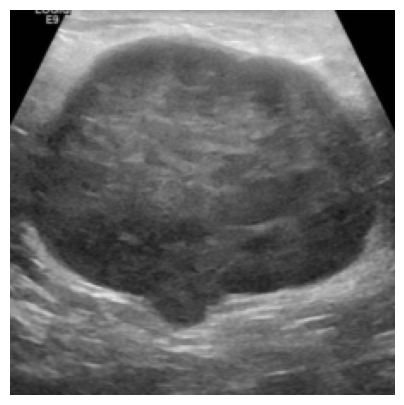

In [ ]:
import matplotlib.pyplot as plt

# Find first malignant image (class 1)
idx = np.where(all_labels == 0)[0][0]

# Get image
img = images[idx]

# CHW -> HWC
img = np.transpose(img, (1, 2, 0))

# Plot
plt.figure(figsize=(5,5))
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
dataset = TensorDataset(X, y)
class0_indices = [i for i in range(len(y)) if y[i] == 0]
class1_indices = [i for i in range(len(y)) if y[i] == 1]

random.seed(SEED)
sampled_class0 = random.sample(class0_indices, min(1000, len(class0_indices)))
sampled_class1 = random.sample(class1_indices, min(1000, len(class1_indices)))

combined_indices = sampled_class0 + sampled_class1
random.shuffle(combined_indices)

final_dataset = Subset(dataset, combined_indices)
final_loader = DataLoader(final_dataset, batch_size=64, shuffle=False)

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
vit = torch.hub.load('facebookresearch/dino:main', 'dino_vitb16')
vit.eval().to(device)

vit_feats, y_list = [], []

with torch.no_grad():
    for imgs, lbls in final_loader:
        imgs = imgs.to(device)
        feats = vit(imgs)
        vit_feats.append(feats.cpu())
        y_list.extend(lbls.cpu().tolist())

F = torch.cat(vit_feats, dim=0).numpy().astype(np.float32)
y = np.array(y_list).astype(np.int64)

num_nodes, num_feats = F.shape
print(f"Extracted ViT-DINO Features: {F.shape}, Labels: {y.shape}")
features = F
y_labels = y
feat_dim = features.shape[1]      # = 768 for ViT-DINO
K = len(np.unique(y_labels))

Using cache found in /home/snu/.cache/torch/hub/facebookresearch_dino_main


Extracted ViT-DINO Features: (780, 768), Labels: (780,)


In [ ]:
def create_adj(features, cut, alpha=1.0):
    F_norm = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-12)
    W = np.dot(F_norm, F_norm.T)
    if cut == 0:
        W = np.where(W >= alpha, 1, 0).astype(np.float32)
        if W.max() > 0:
            W = (W / W.max()).astype(np.float32)
    else:
        W = (W * (W >= alpha)).astype(np.float32)
    return W

def edge_index_from_dense(W):
    rows, cols = np.nonzero(W > 0)
    edge_index = np.vstack([rows, cols]).astype(np.int64)
    edge_weight = W[rows, cols].astype(np.float32)
    return edge_index, edge_weight

def build_adj_list(edge_index_np, num_nodes):
    adj = [[] for _ in range(num_nodes)]
    src = edge_index_np[0]
    dst = edge_index_np[1]
    for s, d in zip(src, dst):
        adj[s].append(d)
    adj = [np.array(neis, dtype=np.int64) if len(neis) > 0 else np.array([], dtype=np.int64) for neis in adj]
    return adj

def aug_random_edge_edge_index(edge_index_np, drop_percent=0.2, seed=None):
    rng = np.random.default_rng(seed)
    E = edge_index_np.shape[1]
    keep_mask = rng.random(E) >= drop_percent
    new_edge_index = edge_index_np[:, keep_mask]
    return new_edge_index

def load_data_from_edge_index(node_feats_np, edge_index_np, device):
    node_feats = torch.from_numpy(node_feats_np).float()
    edge_index = torch.from_numpy(edge_index_np.astype(np.int64)).long()
    return node_feats, edge_index

In [ ]:
def sim(h1, h2, tau=0.2):
    z1 = nnF.normalize(h1, dim=-1, p=2)
    z2 = nnF.normalize(h2, dim=-1, p=2)
    return torch.mm(z1, z2.t()) / tau

def contrastive_loss_wo_cross_network(h1, h2, z):
    f = lambda x: torch.exp(x)
    intra_sim = f(sim(h1, h1))
    inter_sim = f(sim(h1, h2))
    return -torch.log(inter_sim.diag() /
                     (intra_sim.sum(dim=-1) + inter_sim.sum(dim=-1) - intra_sim.diag() + 1e-12))

def contrastive_loss_wo_cross_view(h1, h2, z):
    f = lambda x: torch.exp(x)
    cross_sim = f(sim(h1, z))
    return -torch.log(cross_sim.diag() / (cross_sim.sum(dim=-1) + 1e-12))

In [ ]:
class MLP(nn.Module):
    def __init__(self, inp_size, outp_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.PReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, outp_size)
        )
    def forward(self, x):
        return self.net(x)

class ARMAEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, device,
                 activ="RELU", num_stacks=1, num_layers=1):
        super().__init__()

        activations = {
            "SELU": nnF.selu,
            "SiLU": nnF.silu,
            "GELU": nnF.gelu,
            "ELU": nnF.elu,
            "RELU": nnF.relu
        }
        self.act = activations.get(activ, nnF.elu)

        self.arma = ARMAConv(
            in_channels=input_dim,
            out_channels=hidden_dim,
            num_stacks=num_stacks,
            num_layers=num_layers,
            act=self.act,
            shared_weights=True,
            dropout=0.3
        )

        self.dropout = nn.Dropout(0.3)
        self.mlp = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, data):
        x = self.arma(data.x, data.edge_index)
        x = self.dropout(x)
        return self.mlp(x)


In [ ]:
class EMA():
    def __init__(self, beta):
        self.beta = beta
    def update_average(self, old, new):
        if old is None:
            return new
        return old * self.beta + (1 - self.beta) * new

def update_moving_average(ema_updater, ma_model, current_model):
    for current_params, ma_params in zip(current_model.parameters(), ma_model.parameters()):
        old_weight, up_weight = ma_params.data, current_params.data
        ma_params.data = ema_updater.update_average(old_weight, up_weight)

In [ ]:
class ARMA(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_clusters, device, activ, moving_average_decay=0.99, cut=True):
        super(ARMA, self).__init__()
        self.device = device
        self.num_clusters = num_clusters
        self.cut = cut
        self.beta = 0.6

        self.online_encoder = ARMAEncoder(input_dim, hidden_dim, device, activ)
        self.target_encoder = copy.deepcopy(self.online_encoder)
        for p in self.target_encoder.parameters():
            p.requires_grad = False
        self.online_predictor = MLP(hidden_dim, num_clusters, hidden_dim)
        self.loss = self.cut_loss if cut else self.modularity_loss
        self.target_ema_updater = EMA(moving_average_decay)

    def reset_moving_average(self):
        del self.target_encoder
        self.target_encoder = None

    def update_ma(self):
        assert self.target_encoder is not None, 'target encoder has not been created yet'
        update_moving_average(self.target_ema_updater, self.target_encoder, self.online_encoder)

    def forward(self, data1, data2):
        x1 = self.online_encoder(data1)
        logits1 = self.online_predictor(x1)
        S1 = nnF.softmax(logits1, dim=1)
        x2 = self.online_encoder(data2)
        logits2 = self.online_predictor(x2)
        S2 = nnF.softmax(logits2, dim=1)
        with torch.no_grad():
            target_proj_one = self.target_encoder(data1).detach()
            target_proj_two = self.target_encoder(data2).detach()
        l1 = self.beta * contrastive_loss_wo_cross_network(x1, x2, target_proj_two) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x1, x2, target_proj_two)
        l2 = self.beta * contrastive_loss_wo_cross_network(x2, x1, target_proj_one) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x2, x1, target_proj_one)
        return S1, S2, logits1, logits2, l1, l2

    def modularity_loss(self, A, S):
        C = nnF.softmax(S, dim=1)
        d = torch.sum(A, dim=1)
        m = torch.sum(A)
        B = A - torch.ger(d, d) / (2 * m + 1e-12)
        k = torch.tensor(self.num_clusters, device=self.device, dtype=torch.float32)
        n = S.shape[0]
        modularity_term = (-1.0 / (2.0 * m + 1e-12)) * torch.trace(torch.mm(torch.mm(C.t(), B), C))
        collapse_reg_term = (torch.sqrt(k) / n) * torch.norm(torch.sum(C, dim=0), p='fro') - 1.0
        return modularity_term + collapse_reg_term

    def cut_loss(self, A, S):
        S = nnF.softmax(S, dim=1)
        A_pool = torch.matmul(torch.matmul(A, S).t(), S)
        num = torch.trace(A_pool)
        D = torch.diag(torch.sum(A, dim=-1))
        D_pooled = torch.matmul(torch.matmul(D, S).t(), S)
        den = torch.trace(D_pooled)
        mincut_loss = -(num / (den + 1e-12))
        St_S = torch.matmul(S.t(), S)
        I_S = torch.eye(self.num_clusters, device=self.device)
        ortho_loss = torch.norm(St_S / (torch.norm(St_S) + 1e-12) - I_S / (torch.norm(I_S) + 1e-12))
        return mincut_loss + ortho_loss

In [ ]:
alpha = 0.73
hidden_dim = 256
K = 2
num_epochs = 2000

W0 = create_adj(features, cut=0, alpha=alpha)
edge_index_np, edge_weight_np = edge_index_from_dense(W0)
node_feats_all, edge_index_all = load_data_from_edge_index(features, edge_index_np, device)
data_full = Data(x=node_feats_all.to(device), edge_index=edge_index_all.to(device))
A1 = torch.from_numpy(W0).float().to(device)

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, log_loss, roc_auc_score, roc_curve, auc
)


=== Fold 1 ===
Epoch 0 | Total: 0.648581 | Cont: 6.797913 | CE: 0.771781 | Unsup: -0.123879
Epoch 1 | Total: 0.609803 | Cont: 6.799452 | CE: 0.733327 | Unsup: -0.124204
Epoch 500 | Total: -0.101090 | Cont: 6.147978 | CE: 0.072130 | Unsup: -0.173836
Epoch 1000 | Total: -0.136680 | Cont: 5.999213 | CE: 0.039551 | Unsup: -0.176831
Epoch 1500 | Total: -0.155858 | Cont: 5.956440 | CE: 0.021221 | Unsup: -0.177675
Fold 1 → Acc=0.9772 Prec=0.9825 Rec=0.9864 F1=0.9844 AUC=0.9952

=== Fold 2 ===
Epoch 0 | Total: 1.165275 | Cont: 6.834289 | CE: 1.289747 | Unsup: -0.125155
Epoch 1 | Total: 0.766141 | Cont: 6.826847 | CE: 0.890894 | Unsup: -0.125436
Epoch 500 | Total: -0.095282 | Cont: 6.267608 | CE: 0.078841 | Unsup: -0.174750
Epoch 1000 | Total: -0.112952 | Cont: 6.063811 | CE: 0.063309 | Unsup: -0.176867
Epoch 1500 | Total: -0.140235 | Cont: 5.983572 | CE: 0.036478 | Unsup: -0.177311
Fold 2 → Acc=0.9744 Prec=0.9843 Rec=0.9805 F1=0.9824 AUC=0.9875

=== Fold 3 ===
Epoch 0 | Total: 0.593335 | Cont

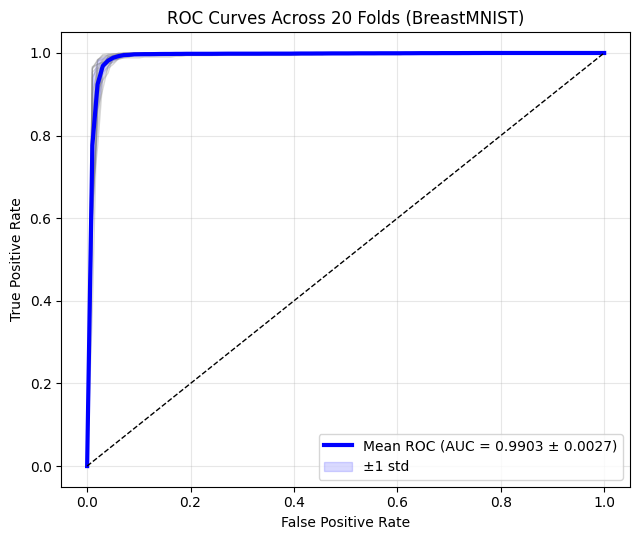

In [ ]:
accuracies, precisions, recalls, f1_scores, losses, all_auc = [], [], [], [], [], []
mean_fpr = np.linspace(0, 1, 100)
tprs = []
auc_per_fold = []


sss = StratifiedShuffleSplit(n_splits=20, test_size=0.9, random_state=SEED)
for fold, (train_idx_full, test_idx) in enumerate(sss.split(features, y_labels)):
    print(f"\n=== Fold {fold+1} ===")

    cn_idx = np.where(y_labels == 0)[0]
    mci_idx = np.where(y_labels == 1)[0]
    sss_class = StratifiedShuffleSplit(n_splits=20, test_size=0.2, random_state=fold)
    cn_train_idx, _ = next(sss_class.split(features[cn_idx], y_labels[cn_idx]))
    mci_train_idx, _ = next(sss_class.split(features[mci_idx], y_labels[mci_idx]))
    cn_train = cn_idx[cn_train_idx]
    mci_train = mci_idx[mci_train_idx]
    balanced_train_idx = np.concatenate([cn_train, mci_train])
    np.random.shuffle(balanced_train_idx)

    train_idx_t = torch.from_numpy(balanced_train_idx).long().to(device)
    test_idx_t = torch.from_numpy(test_idx).long().to(device)
    y_tensor = torch.from_numpy(y_labels).long().to(device)

    model = ARMA(feat_dim, hidden_dim, K, device, activ="RELU", cut=False, moving_average_decay=0.99).to(device)
    classifier = nn.Linear(hidden_dim, K).to(device)
    optimizer = optim.Adam(list(model.parameters()) + list(classifier.parameters()), lr=1e-4, weight_decay=1e-4)
    ce_loss = nn.CrossEntropyLoss()

    for ep in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        edge_index_aug1 = aug_random_edge_edge_index(edge_index_np, drop_percent=0.2, seed=ep)
        edge_index_aug2 = aug_random_edge_edge_index(edge_index_np, drop_percent=0.2, seed=ep+999)
        rng = np.random.default_rng(ep)
        mask = rng.random(features.shape) >= 0.2
        features_aug1 = (features * mask.astype(np.float32))
        aug_feat2 = features.copy()
        drop_feat_num = int(features.shape[0] * features.shape[1] * 0.2)
        flat_idx = rng.choice(features.shape[0] * features.shape[1], size=drop_feat_num, replace=False)
        rows = (flat_idx // features.shape[1])
        cols = (flat_idx % features.shape[1])
        aug_feat2[rows, cols] = 0.0
        features_aug2 = aug_feat2.astype(np.float32)
        node_feats1, edge_index1 = load_data_from_edge_index(features_aug1, edge_index_aug1, device)
        data1 = Data(x=node_feats1.to(device), edge_index=edge_index1.to(device))
        node_feats2, edge_index2 = load_data_from_edge_index(features_aug2, edge_index_aug2, device)
        data2 = Data(x=node_feats2.to(device), edge_index=edge_index2.to(device))
        S1, S2, logits1, logits2, l1, l2 = model(data1, data2)
        cont_loss = ((l1 + l2) / 2.0).mean()
        embeddings = model.online_encoder(data_full)
        logits_sup = classifier(embeddings[train_idx_t])
        sup_loss = ce_loss(logits_sup, y_tensor[train_idx_t])
        unsup_loss = model.loss(A1, logits1)
        loss = 0.0001 * cont_loss + sup_loss + unsup_loss
        loss.backward()
        optimizer.step()
        model.update_ma()

        if ep % 500 == 0 or ep == 1:
            print(f"Epoch {ep} | Total: {loss.item():.6f} | Cont: {cont_loss.item():.6f} | CE: {sup_loss.item():.6f} | Unsup: {unsup_loss.item():.6f}")

    # --- Eval ---
    model.eval()
    classifier.eval()
    with torch.no_grad():
        embeddings_final = model.online_encoder(data_full)
        logits_final = classifier(embeddings_final)
        probs = nnF.softmax(logits_final, dim=1).cpu().numpy()
        y_pred = np.argmax(probs, axis=1)

    y_test = y_labels[test_idx]
    y_pred_test = y_pred[test_idx]
    y_proba_test = probs[test_idx, 1] if probs.shape[1] > 1 else probs[test_idx, 0]

    acc = accuracy_score(y_test, y_pred_test)
    prec = precision_score(y_test, y_pred_test, zero_division=0)
    rec = recall_score(y_test, y_pred_test, zero_division=0)
    f1 = f1_score(y_test, y_pred_test, zero_division=0)
    try:
        loss_val = log_loss(y_test, y_proba_test)
    except:
        loss_val = np.nan
    try:
        auc_score = roc_auc_score(y_test, y_proba_test)
    except:
        auc_score = np.nan
    try:
        fpr, tpr, _ = roc_curve(y_test, y_proba_test)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        auc_per_fold.append(auc_score)
    except Exception:
        pass

    print(f"Fold {fold+1} → Acc={acc:.4f} Prec={prec:.4f} Rec={rec:.4f} F1={f1:.4f} AUC={auc_score:.4f}")
    accuracies.append(acc)
    precisions.append(prec)
    recalls.append(rec)
    f1_scores.append(f1)
    losses.append(loss_val)
    all_auc.append(auc_score)

print("\n=== Average Results ===")
print(f"Accuracy: {np.nanmean(accuracies):.4f} ± {np.nanstd(accuracies):.4f}")
print(f"Precision: {np.nanmean(precisions):.4f} ± {np.nanstd(precisions):.4f}")
print(f"Recall: {np.nanmean(recalls):.4f} ± {np.nanstd(recalls):.4f}")
print(f"F1: {np.nanmean(f1_scores):.4f} ± {np.nanstd(f1_scores):.4f}")
print(f"LogLoss: {np.nanmean(losses):.4f} ± {np.nanstd(losses):.4f}")
print(f"AUC: {np.nanmean(all_auc):.4f} ± {np.nanstd(all_auc):.4f}")
# -------------------------
# Plot ROC curves (all folds + mean)
# -------------------------
mean_tpr = np.mean(tprs, axis=0)
std_tpr = np.std(tprs, axis=0)
mean_tpr[-1] = 1.0

mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.nanstd(auc_per_fold)

plt.figure(figsize=(6.5, 5.5))

# Individual folds
for i in range(len(tprs)):
    plt.plot(mean_fpr, tprs[i], color="gray", lw=1, alpha=0.3)

# Mean ROC (highlighted)
plt.plot(
    mean_fpr,
    mean_tpr,
    color="blue",
    lw=3,
    label=f"Mean ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})"
)

# Std band
plt.fill_between(
    mean_fpr,
    np.maximum(mean_tpr - std_tpr, 0),
    np.minimum(mean_tpr + std_tpr, 1),
    color="blue",
    alpha=0.15,
    label="±1 std"
)

plt.plot([0, 1], [0, 1], linestyle="--", color="black", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Across 20 Folds (BreastMNIST)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


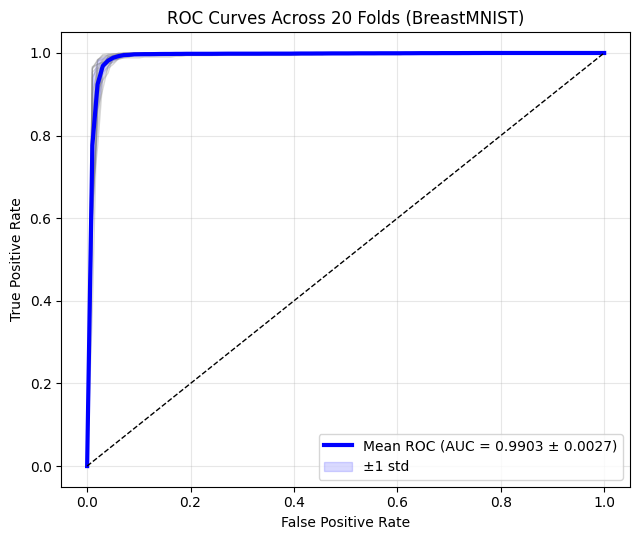

In [ ]:
import matplotlib.pyplot as plt
mean_tpr = np.mean(tprs, axis=0)
std_tpr = np.std(tprs, axis=0)
mean_tpr[-1] = 1.0

mean_auc = auc(mean_fpr, mean_tpr)
std_auc = np.nanstd(auc_per_fold)

plt.figure(figsize=(6.5, 5.5))

# Individual folds
for i in range(len(tprs)):
    plt.plot(mean_fpr, tprs[i], color="gray", lw=1, alpha=0.3)

# Mean ROC (highlighted)
plt.plot(
    mean_fpr,
    mean_tpr,
    color="blue",
    lw=3,
    label=f"Mean ROC (AUC = {mean_auc:.4f} ± {std_auc:.4f})"
)

# Std band
plt.fill_between(
    mean_fpr,
    np.maximum(mean_tpr - std_tpr, 0),
    np.minimum(mean_tpr + std_tpr, 1),
    color="blue",
    alpha=0.15,
    label="±1 std"
)

plt.plot([0, 1], [0, 1], linestyle="--", color="black", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Across 20 Folds (BreastMNIST)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
# -*- coding: utf-8 -*-
"""
ARMA-C3 Ablation Study on BreastMNIST
Ablation over:
  1. activation function  (activ)
  2. graph threshold      (alpha)
  3. contrastive weight   (lambda_con)
  4. structural weight    (lambda_struct)
Same 20-fold protocol as the main ARMA-C3 BreastMNIST code.
Features: ViT-DINO (frozen) on 224x224 breast ultrasound images.
"""

import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as nnF
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import ARMAConv
from torch.utils.data import TensorDataset, DataLoader, Subset
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, log_loss, roc_auc_score,
)

# ============================================================
# Reproducibility
# ============================================================
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ============================================================
# Load BreastMNIST 224x224 and extract ViT-DINO features (once)
# ============================================================
data = np.load("/home/snu/Downloads/breastmnist_224.npz", allow_pickle=True)

all_images = np.concatenate(
    [data["train_images"], data["val_images"], data["test_images"]], axis=0
)
all_labels = np.concatenate(
    [data["train_labels"], data["val_labels"], data["test_labels"]], axis=0
).squeeze()

images = all_images.astype(np.float32) / 255.0
images = np.repeat(images[:, None, :, :], 3, axis=1)  # (N,3,224,224)

X_img = torch.tensor(images)
y_all_t = torch.tensor(all_labels).long()
print("Images, labels shapes:", X_img.shape, y_all_t.shape)

# Balanced subset (same as main BreastMNIST code)
dataset = TensorDataset(X_img, y_all_t)
class0_indices = [i for i in range(len(y_all_t)) if y_all_t[i] == 0]
class1_indices = [i for i in range(len(y_all_t)) if y_all_t[i] == 1]

random.seed(SEED)
sampled_class0 = random.sample(class0_indices, min(1000, len(class0_indices)))
sampled_class1 = random.sample(class1_indices, min(1000, len(class1_indices)))

combined_indices = sampled_class0 + sampled_class1
random.shuffle(combined_indices)

final_dataset = Subset(dataset, combined_indices)
final_loader = DataLoader(final_dataset, batch_size=64, shuffle=False)

# ViT-DINO feature extraction (frozen)
vit = torch.hub.load("facebookresearch/dino:main", "dino_vitb16")
vit.eval().to(device)

vit_feats, y_list = [], []
with torch.no_grad():
    for imgs, lbls in final_loader:
        imgs = imgs.to(device)
        feats = vit(imgs)
        vit_feats.append(feats.cpu())
        y_list.extend(lbls.cpu().tolist())

features = torch.cat(vit_feats, dim=0).numpy().astype(np.float32)
y = np.array(y_list).astype(np.int64)

num_nodes, feat_dim = features.shape
print(f"Extracted ViT-DINO features: {features.shape}, Labels: {y.shape}")
print(f"Class 0: {int((y==0).sum())}, Class 1: {int((y==1).sum())}")

# ============================================================
# Building blocks (identical to main BreastMNIST ARMA-C3 code)
# ============================================================
def sim(h1, h2, tau=0.2):
    z1 = nnF.normalize(h1, dim=-1, p=2)
    z2 = nnF.normalize(h2, dim=-1, p=2)
    return torch.mm(z1, z2.t()) / tau


def contrastive_loss_wo_cross_network(h1, h2, z, tau):
    f = lambda x: torch.exp(x)
    intra_sim = f(sim(h1, h1, tau))
    inter_sim = f(sim(h1, h2, tau))
    return -torch.log(inter_sim.diag() /
                      (intra_sim.sum(dim=-1) + inter_sim.sum(dim=-1) - intra_sim.diag() + 1e-12))


def contrastive_loss_wo_cross_view(h1, h2, z, tau):
    f = lambda x: torch.exp(x)
    cross_sim = f(sim(h1, z, tau))
    return -torch.log(cross_sim.diag() / (cross_sim.sum(dim=-1) + 1e-12))


class MLP(nn.Module):
    def __init__(self, inp_size, outp_size, hidden_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.PReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_size, outp_size),
        )
    def forward(self, x):
        return self.net(x)


class ARMAEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dim, device, activ="RELU",
                 num_stacks=1, num_layers=1):
        super().__init__()
        self.device = device
        activations = {
            "SELU": nnF.selu,
            "SiLU": nnF.silu,
            "GELU": nnF.gelu,
            "ELU":  nnF.elu,
            "RELU": nnF.relu,
        }
        self.act = activations.get(activ, nnF.elu)
        self.arma = ARMAConv(
            in_channels=input_dim,
            out_channels=hidden_dim,
            num_stacks=num_stacks,
            num_layers=num_layers,
            act=self.act,
            shared_weights=True,
            dropout=0.3,
        )
        self.dropout = nn.Dropout(0.3)
        self.mlp = nn.Linear(hidden_dim, hidden_dim)

    def forward(self, data):
        x = self.arma(data.x, data.edge_index)
        x = self.dropout(x)
        return self.mlp(x)


class EMA():
    def __init__(self, beta):
        self.beta = beta
    def update_average(self, old, new):
        if old is None:
            return new
        return old * self.beta + (1 - self.beta) * new


def update_moving_average(ema_updater, ma_model, current_model):
    for current_params, ma_params in zip(current_model.parameters(), ma_model.parameters()):
        old_weight, up_weight = ma_params.data, current_params.data
        ma_params.data = ema_updater.update_average(old_weight, up_weight)


class ARMA(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_clusters, device,
                 activ, moving_average_decay=0.9999, cut=False, tau=0.10, beta=0.30):
        super().__init__()
        self.device       = device
        self.num_clusters = num_clusters
        self.cut          = cut
        self.beta         = beta
        self.tau          = tau

        self.online_encoder = ARMAEncoder(input_dim, hidden_dim, device, activ)
        self.target_encoder = copy.deepcopy(self.online_encoder)
        for p in self.target_encoder.parameters():
            p.requires_grad = False

        self.online_predictor = MLP(hidden_dim, num_clusters, hidden_dim)
        self.loss = self.cut_loss if cut else self.modularity_loss
        self.target_ema_updater = EMA(moving_average_decay)

    def update_ma(self):
        update_moving_average(self.target_ema_updater, self.target_encoder, self.online_encoder)

    def forward(self, data1, data2):
        x1 = self.online_encoder(data1)
        logits1 = self.online_predictor(x1)
        S1 = nnF.softmax(logits1, dim=1)

        x2 = self.online_encoder(data2)
        logits2 = self.online_predictor(x2)
        S2 = nnF.softmax(logits2, dim=1)

        with torch.no_grad():
            target_proj_one = self.target_encoder(data1).detach()
            target_proj_two = self.target_encoder(data2).detach()

        l1 = self.beta * contrastive_loss_wo_cross_network(x1, x2, target_proj_two, self.tau) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x1, x2, target_proj_two, self.tau)
        l2 = self.beta * contrastive_loss_wo_cross_network(x2, x1, target_proj_one, self.tau) + \
             (1.0 - self.beta) * contrastive_loss_wo_cross_view(x2, x1, target_proj_one, self.tau)
        return S1, S2, logits1, logits2, l1, l2

    def modularity_loss(self, A, S):
        C = nnF.softmax(S, dim=1)
        d = torch.sum(A, dim=1)
        m = torch.sum(A)
        B = A - torch.ger(d, d) / (2 * m + 1e-12)
        k = torch.tensor(self.num_clusters, device=self.device, dtype=torch.float32)
        n = S.shape[0]
        modularity_term   = (-1.0 / (2.0 * m + 1e-12)) * torch.trace(torch.mm(torch.mm(C.t(), B), C))
        collapse_reg_term = (torch.sqrt(k) / n) * torch.norm(torch.sum(C, dim=0), p='fro') - 1.0
        return modularity_term + collapse_reg_term

    def cut_loss(self, A, S):
        S = nnF.softmax(S, dim=1)
        A_pool = torch.matmul(torch.matmul(A, S).t(), S)
        num = torch.trace(A_pool)
        D = torch.diag(torch.sum(A, dim=-1))
        D_pooled = torch.matmul(torch.matmul(D, S).t(), S)
        den = torch.trace(D_pooled)
        mincut_loss = -(num / (den + 1e-12))
        St_S = torch.matmul(S.t(), S)
        I_S  = torch.eye(self.num_clusters, device=self.device)
        ortho_loss = torch.norm(St_S / (torch.norm(St_S) + 1e-12) - I_S / (torch.norm(I_S) + 1e-12))
        return mincut_loss + ortho_loss


def create_adj(features, cut, alpha=1.0):
    F_norm = features / (np.linalg.norm(features, axis=1, keepdims=True) + 1e-12)
    W = np.dot(F_norm, F_norm.T)
    if cut == 0:
        W = np.where(W >= alpha, 1, 0).astype(np.float32)
        if W.max() > 0:
            W = (W / W.max()).astype(np.float32)
    else:
        W = (W * (W >= alpha)).astype(np.float32)
    return W


def edge_index_from_dense(W):
    rows, cols = np.nonzero(W > 0)
    return np.vstack([rows, cols]).astype(np.int64)


def aug_random_edge_edge_index(edge_index_np, drop_percent=0.2, seed=None):
    rng = np.random.default_rng(seed)
    E = edge_index_np.shape[1]
    keep_mask = rng.random(E) >= drop_percent
    return edge_index_np[:, keep_mask]


def load_data_from_edge_index(node_feats_np, edge_index_np, device):
    node_feats = torch.from_numpy(node_feats_np).float()
    edge_index = torch.from_numpy(edge_index_np.astype(np.int64)).long()
    return node_feats, edge_index


# ============================================================
# Single 20-fold experiment
# ============================================================
def run_experiment(activ, alpha, lambda_con, lambda_struct,
                   hidden_dim=256, K=2, num_epochs=2500,
                   lr=1e-4, weight_decay=5e-5,
                   tau=0.10, beta=0.30, moving_average_decay=0.9999,
                   n_splits=20, test_size=0.9, inner_test_size=0.9,
                   verbose=False):
    """
    Runs 20-fold CV for one BreastMNIST hyperparameter config.
    Default LR/WD/Epochs match Table 1 Breast row.
    """
    # Build graph for this alpha
    W0 = create_adj(features, cut=0, alpha=alpha)
    edge_index_np = edge_index_from_dense(W0)
    node_feats_all, edge_index_all = load_data_from_edge_index(features, edge_index_np, device)
    data_full = Data(x=node_feats_all.to(device), edge_index=edge_index_all.to(device))
    A1 = torch.from_numpy(W0).float().to(device)

    accuracies, precisions, recalls, f1_scores, losses, all_auc = [], [], [], [], [], []

    sss = StratifiedShuffleSplit(n_splits=n_splits, test_size=test_size, random_state=SEED)

    for fold, (train_idx_full, test_idx) in enumerate(sss.split(features, y)):
        class0_idx = np.where(y == 0)[0]
        class1_idx = np.where(y == 1)[0]

        sss_class = StratifiedShuffleSplit(n_splits=20, test_size=inner_test_size, random_state=fold)
        c0_train_idx, _ = next(sss_class.split(features[class0_idx], y[class0_idx]))
        c1_train_idx, _ = next(sss_class.split(features[class1_idx], y[class1_idx]))

        balanced_train_idx = np.concatenate([
            class0_idx[c0_train_idx],
            class1_idx[c1_train_idx],
        ])
        np.random.shuffle(balanced_train_idx)

        train_idx_t = torch.from_numpy(balanced_train_idx).long().to(device)
        y_tensor    = torch.from_numpy(y).long().to(device)

        # Per-fold seeding
        torch.manual_seed(SEED + fold)
        np.random.seed(SEED + fold)

        model = ARMA(
            feat_dim, hidden_dim, K, device,
            activ=activ, cut=False,     # modularity-based structural regularization
            moving_average_decay=moving_average_decay,
            tau=tau, beta=beta,
        ).to(device)

        classifier = nn.Linear(hidden_dim, K).to(device)
        optimizer = optim.Adam(
            list(model.parameters()) + list(classifier.parameters()),
            lr=lr, weight_decay=weight_decay,
        )
        ce_loss = nn.CrossEntropyLoss()

        for ep in range(num_epochs):
            model.train()
            optimizer.zero_grad()

            edge_index_aug1 = aug_random_edge_edge_index(edge_index_np, 0.2, seed=ep)
            edge_index_aug2 = aug_random_edge_edge_index(edge_index_np, 0.2, seed=ep + 999)

            rng = np.random.default_rng(ep)
            mask = rng.random(features.shape) >= 0.2
            features_aug1 = features * mask.astype(np.float32)

            aug_feat2 = features.copy()
            drop_feat_num = int(features.size * 0.2)
            flat_idx = rng.choice(features.size, drop_feat_num, replace=False)
            rows = flat_idx // features.shape[1]
            cols = flat_idx %  features.shape[1]
            aug_feat2[rows, cols] = 0.0
            features_aug2 = aug_feat2.astype(np.float32)

            node_feats1, edge_index1 = load_data_from_edge_index(features_aug1, edge_index_aug1, device)
            node_feats2, edge_index2 = load_data_from_edge_index(features_aug2, edge_index_aug2, device)

            data1 = Data(x=node_feats1.to(device), edge_index=edge_index1.to(device))
            data2 = Data(x=node_feats2.to(device), edge_index=edge_index2.to(device))

            S1, S2, logits1, logits2, l1, l2 = model(data1, data2)
            cont_loss = ((l1 + l2) / 2.0).mean()

            embeddings = model.online_encoder(data_full)
            logits_sup = classifier(embeddings[train_idx_t])
            sup_loss   = ce_loss(logits_sup, y_tensor[train_idx_t])

            struct_loss = model.loss(A1, logits1)

            loss = sup_loss + lambda_con * cont_loss + lambda_struct * struct_loss
            loss.backward()
            optimizer.step()
            model.update_ma()

        # Evaluation
        model.eval()
        classifier.eval()
        with torch.no_grad():
            emb    = model.online_encoder(data_full)
            logits = classifier(emb)
            probs  = nnF.softmax(logits, dim=1).cpu().numpy()
            y_pred = np.argmax(probs, axis=1)

        y_test       = y[test_idx]
        y_pred_test  = y_pred[test_idx]
        y_proba_test = probs[test_idx, 1]

        acc  = accuracy_score(y_test, y_pred_test)
        prec = precision_score(y_test, y_pred_test, zero_division=0)
        rec  = recall_score(y_test, y_pred_test, zero_division=0)
        f1   = f1_score(y_test, y_pred_test, zero_division=0)
        try:    lv = log_loss(y_test, y_proba_test)
        except: lv = np.nan
        try:    auc_sc = roc_auc_score(y_test, y_proba_test)
        except: auc_sc = np.nan

        accuracies.append(acc);  precisions.append(prec)
        recalls.append(rec);     f1_scores.append(f1)
        losses.append(lv);       all_auc.append(auc_sc)

        if verbose:
            print(f"     Fold {fold+1}: Acc={acc:.4f} F1={f1:.4f} AUC={auc_sc:.4f}")

    return {
        "Accuracy":     float(np.nanmean(accuracies)),
        "Accuracy_std": float(np.nanstd(accuracies)),
        "Precision":    float(np.nanmean(precisions)),
        "Recall":       float(np.nanmean(recalls)),
        "F1":           float(np.nanmean(f1_scores)),
        "LogLoss":      float(np.nanmean(losses)),
        "AUC":          float(np.nanmean(all_auc)),
        "AUC_std":      float(np.nanstd(all_auc)),
    }


# ============================================================
# Ablation configuration (BreastMNIST reference values from Table 1)
# ============================================================
# Table 1 row for Breast:
#   Act = ReLU, α = 0.63, τ = 0.10, β = 0.30,
#   EMA = 0.9999, λ_con = 1e-4, λ_struct = 1.0,
#   LR = 1e-4, WD = 5e-5, Epochs = 2500
DEFAULTS = dict(
    activ="RELU",
    alpha=0.63,
    lambda_con=1e-4,
    lambda_struct=1.0,
)

ABLATIONS = {
    "activation":    ["RELU", "ELU", "SELU", "GELU"],
    "alpha":         [0.50, 0.55, 0.63, 0.70],
    "lambda_con":    [0.0, 1e-5, 1e-4, 1e-3],
    "lambda_struct": [0.0, 0.5, 1.0, 2.0],
}

# Run one group at a time if time-constrained, e.g. RUN = ["activation"]
RUN = ["activation", "alpha", "lambda_con", "lambda_struct"]

all_results = {}

for abl_name in RUN:
    print(f"\n{'='*70}")
    print(f"ABLATION (BreastMNIST): {abl_name}")
    print(f"{'='*70}")
    all_results[abl_name] = {}

    for value in ABLATIONS[abl_name]:
        cfg = DEFAULTS.copy()
        cfg[abl_name] = value

        print(f"\n>>> {abl_name} = {value}  (others fixed at BreastMNIST default)")

        res = run_experiment(
            activ=cfg["activ"],
            alpha=cfg["alpha"],
            lambda_con=cfg["lambda_con"],
            lambda_struct=cfg["lambda_struct"],
            # Table 1 Breast values already set as function defaults:
            # tau=0.10, beta=0.30, moving_average_decay=0.9999,
            # lr=1e-4, weight_decay=5e-5, num_epochs=2500
        )
        all_results[abl_name][value] = res
        print(f"    Acc={res['Accuracy']:.4f}  F1={res['F1']:.4f}  AUC={res['AUC']:.4f}")

# ============================================================
# Summary tables
# ============================================================
print("\n\n" + "="*70)
print("ABLATION SUMMARY (BreastMNIST, 20-fold)")
print("="*70)

for abl_name, results in all_results.items():
    print(f"\n{abl_name}")
    print(f"  {'Value':<12} {'Accuracy':<12} {'F1':<12} {'AUC':<12}")
    print(f"  {'-'*48}")
    for val, res in results.items():
        print(f"  {str(val):<12} {res['Accuracy']:.4f}      {res['F1']:.4f}      {res['AUC']:.4f}")

    # Sensitivity (max − min) — useful for the rebuttal
    accs = [r["Accuracy"] for r in results.values()]
    f1s  = [r["F1"]       for r in results.values()]
    aucs = [r["AUC"]      for r in results.values()]
    print(f"  Spread (max − min):  Acc={max(accs)-min(accs):.4f}  "
          f"F1={max(f1s)-min(f1s):.4f}  AUC={max(aucs)-min(aucs):.4f}")

/home/snu/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Images, labels shapes: torch.Size([780, 3, 224, 224]) torch.Size([780])


Using cache found in /home/snu/.cache/torch/hub/facebookresearch_dino_main


Extracted ViT-DINO features: (780, 768), Labels: (780,)
Class 0: 210, Class 1: 570

ABLATION (BreastMNIST): activation

>>> activation = RELU  (others fixed at BreastMNIST default)
    Acc=0.8572  F1=0.9035  AUC=0.8959

>>> activation = ELU  (others fixed at BreastMNIST default)
    Acc=0.8566  F1=0.9031  AUC=0.8951

>>> activation = SELU  (others fixed at BreastMNIST default)
    Acc=0.8562  F1=0.9028  AUC=0.8955

>>> activation = GELU  (others fixed at BreastMNIST default)
    Acc=0.8545  F1=0.9015  AUC=0.8958

ABLATION (BreastMNIST): alpha

>>> alpha = 0.5  (others fixed at BreastMNIST default)
    Acc=0.8572  F1=0.9034  AUC=0.8982

>>> alpha = 0.55  (others fixed at BreastMNIST default)
    Acc=0.8557  F1=0.9020  AUC=0.8985

>>> alpha = 0.63  (others fixed at BreastMNIST default)
    Acc=0.8555  F1=0.9021  AUC=0.8954

>>> alpha = 0.7  (others fixed at BreastMNIST default)
    Acc=0.8543  F1=0.9010  AUC=0.8923

ABLATION (BreastMNIST): lambda_con

>>> lambda_con = 0.0  (others fixed 